# Exploratory Data Analysis

Exploratory Data Analysis (EDA) is the structured process of understanding a dataset before modelling.
It reveals data-quality problems, distributional shapes, relationships, and potential modelling risks.

This notebook uses the built-in Wine dataset (chemical analysis of wines from three cultivars) to
demonstrate a practical EDA workflow:

1. structural inspection,
2. data quality checks,
3. univariate analysis,
4. target analysis,
5. bivariate and multivariate analysis,
6. outlier screening,
7. an EDA checklist.

## Learning objectives

1. Inspect a dataset's shape, types, and missingness.
2. Summarise and visualise distributions.
3. Compare feature distributions across target classes.
4. Identify correlated and discriminative features.
5. Screen for outliers without automatically deleting them.
6. Translate EDA findings into modelling decisions.

## 1. Concepts

### What EDA is for

- **Data quality**: missing values, duplicates, impossible values, inconsistent categories.
- **Distributions**: skew, multimodality, scale, outliers.
- **Relationships**: correlation, class separation, interactions.
- **Modelling implications**: scaling, encoding, feature selection, validation strategy.

### Guiding principles

- Look at the data before modelling it.
- Plot distributions; summary statistics can hide structure.
- Compare features by target class when supervised learning is the goal.
- Treat outliers as information first, not automatically as errors.
- Record findings; EDA is part of reproducibility.

## 2. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.feature_selection import f_classif

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## 3. Load the data

The Wine dataset contains 178 samples, 13 numeric features, and 3 cultivar classes. It has no missing
values, which makes it convenient for learning EDA mechanics.

In [2]:
wine = load_wine(as_frame=True)
df = wine.frame.copy()
df["cultivar"] = df["target"].map({0: "class_0", 1: "class_1", 2: "class_2"})
df = df.drop(columns="target")
feature_names = wine.feature_names

print("Shape:", df.shape)
df.head()

Shape: (178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,cultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,class_0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  culti

In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


## 4. Data quality checks

Check for missing values, duplicate rows, and unexpected category values. Duplicates may be legitimate
measurements, so investigate before removing them.

In [5]:
quality = pd.DataFrame({
    "missing": df.isna().sum(),
    "unique": df.nunique(),
    "dtype": df.dtypes.astype(str),
})
print("Total missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
quality

Total missing values: 0
Duplicate rows: 0


,missing,unique,dtype
alcohol,0,126,float64
malic_acid,0,133,float64
ash,0,79,float64
alcalinity_of_ash,0,63,float64
magnesium,0,53,float64
total_phenols,0,97,float64
flavanoids,0,132,float64
nonflavanoid_phenols,0,39,float64
proanthocyanins,0,101,float64
color_intensity,0,132,float64


## 5. Univariate analysis

### Target balance

Class balance affects metric choice, cross-validation strategy, and whether resampling is needed.

cultivar
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64
cultivar
class_0    0.331
class_1    0.399
class_2    0.270
Name: count, dtype: float64


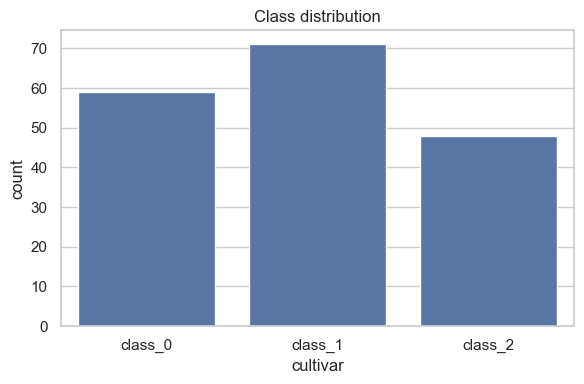

In [6]:
class_counts = df["cultivar"].value_counts().sort_index()
print(class_counts)
print((class_counts / len(df)).round(3))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="cultivar", order=class_counts.index)
plt.title("Class distribution")
plt.tight_layout()
plt.show()

### Feature distributions

Histograms expose skew and multimodality. The features are measured on very different scales, which
matters for distance-based and regularised linear models.

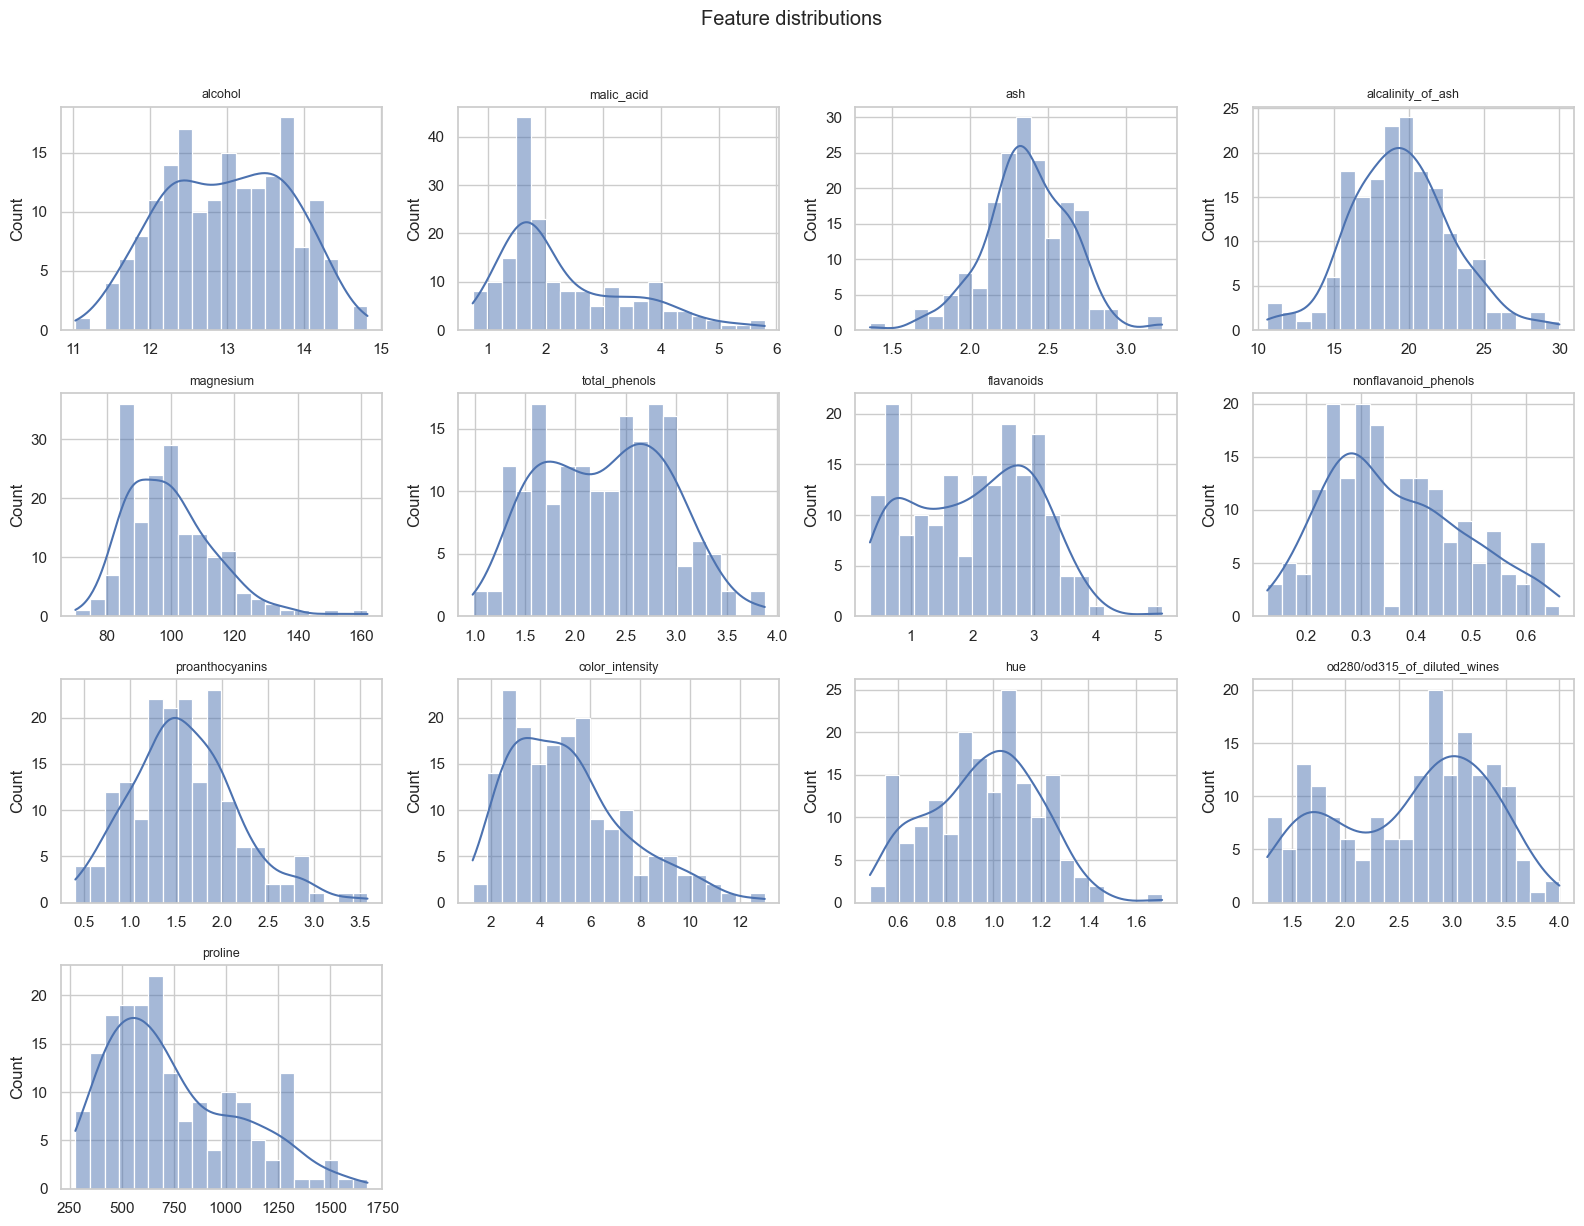

In [7]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
axes = axes.ravel()

for ax, column in zip(axes, feature_names):
    sns.histplot(df[column], bins=20, kde=True, ax=ax)
    ax.set_title(column, fontsize=9)
    ax.set_xlabel("")

for ax in axes[len(feature_names):]:
    ax.axis("off")

plt.suptitle("Feature distributions", y=1.02)
plt.tight_layout()
plt.show()

In [8]:
skewness = df[feature_names].skew().sort_values(ascending=False)
skewness.round(3)

magnesium                       1.098
malic_acid                      1.040
color_intensity                 0.869
proline                         0.768
proanthocyanins                 0.517
nonflavanoid_phenols            0.450
alcalinity_of_ash               0.213
total_phenols                   0.087
flavanoids                      0.025
hue                             0.021
alcohol                        -0.051
ash                            -0.177
od280/od315_of_diluted_wines   -0.307
dtype: float64

Skewed features may benefit from a log or power transform for linear models. Tree-based models are
usually unaffected by monotonic transformations.

## 6. Target analysis

Compare feature means across cultivars. Large differences suggest useful predictors; overlapping
distributions suggest weaker signals.

In [9]:
class_means = df.groupby("cultivar")[feature_names].mean().T
class_means.round(2)

cultivar,class_0,class_1,class_2
alcohol,13.74,12.28,13.15
malic_acid,2.01,1.93,3.33
ash,2.46,2.24,2.44
alcalinity_of_ash,17.04,20.24,21.42
magnesium,106.34,94.55,99.31
total_phenols,2.84,2.26,1.68
flavanoids,2.98,2.08,0.78
nonflavanoid_phenols,0.29,0.36,0.45
proanthocyanins,1.90,1.63,1.15
color_intensity,5.53,3.09,7.40


In [10]:
f_scores, p_values = f_classif(df[feature_names], df["cultivar"])
discrimination = pd.DataFrame({
    "feature": feature_names,
    "f_score": f_scores,
    "p_value": p_values,
}).sort_values("f_score", ascending=False)
discrimination.round(4)

,feature,f_score,p_value
6,flavanoids,233.9259,0.0
12,proline,207.9204,0.0
11,od280/od315_of_diluted_wines,189.9723,0.0
0,alcohol,135.0776,0.0
9,color_intensity,120.6640,0.0
10,hue,101.3168,0.0
5,total_phenols,93.7330,0.0
1,malic_acid,36.9434,0.0
3,alcalinity_of_ash,35.7716,0.0
8,proanthocyanins,30.2714,0.0


## 7. Bivariate analysis

### Distributions by class

Boxplots show medians, spread, and class separation. They also reveal outliers.

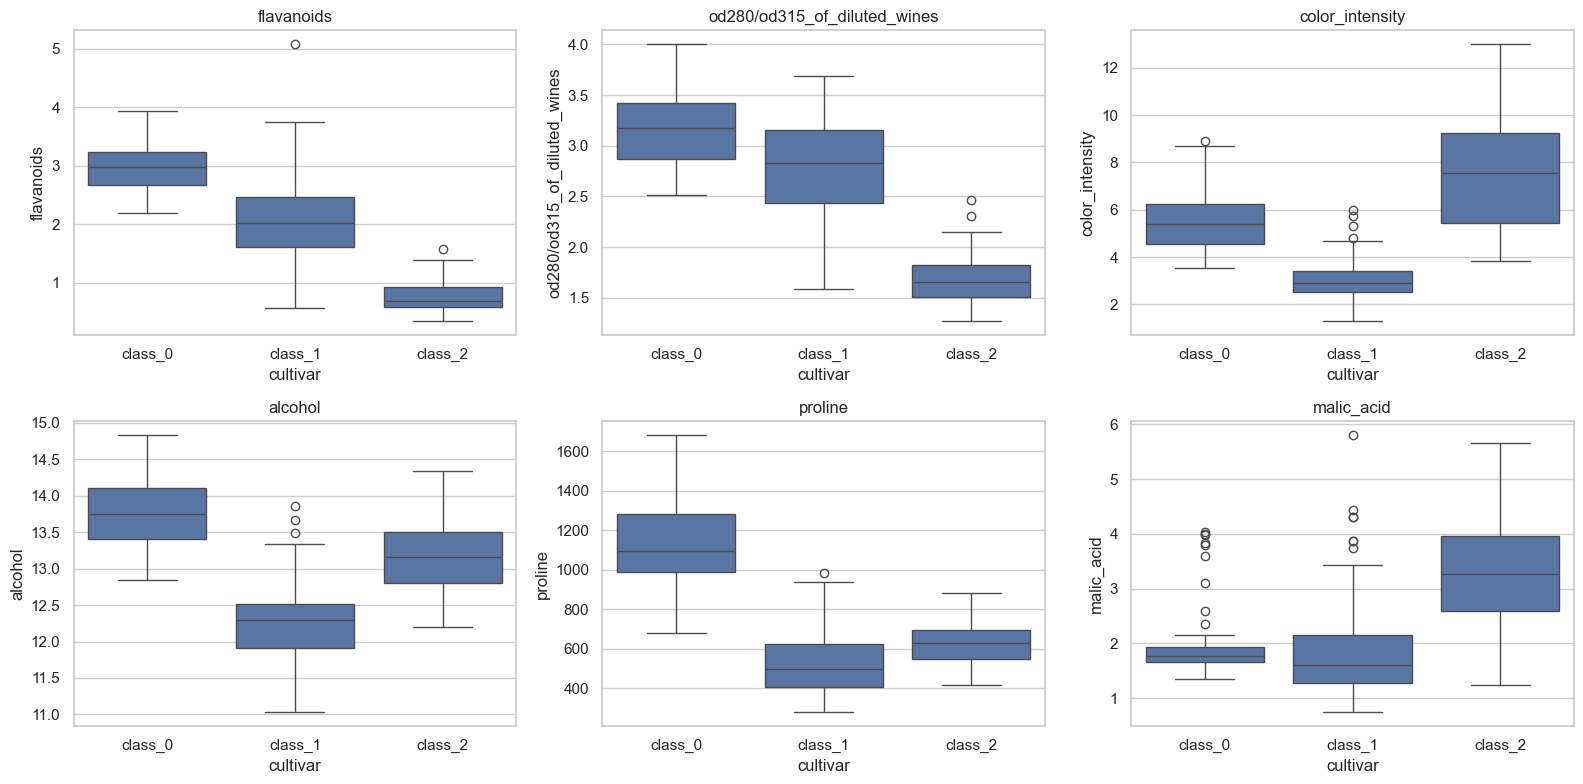

In [11]:
selected = ["flavanoids", "od280/od315_of_diluted_wines", "color_intensity", "alcohol", "proline", "malic_acid"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, column in zip(axes.ravel(), selected):
    sns.boxplot(data=df, x="cultivar", y=column, ax=ax)
    ax.set_title(column)
plt.tight_layout()
plt.show()

### Correlation

Correlation describes linear association. Highly correlated features carry redundant information and
can destabilise linear models; regularisation or feature selection may help.

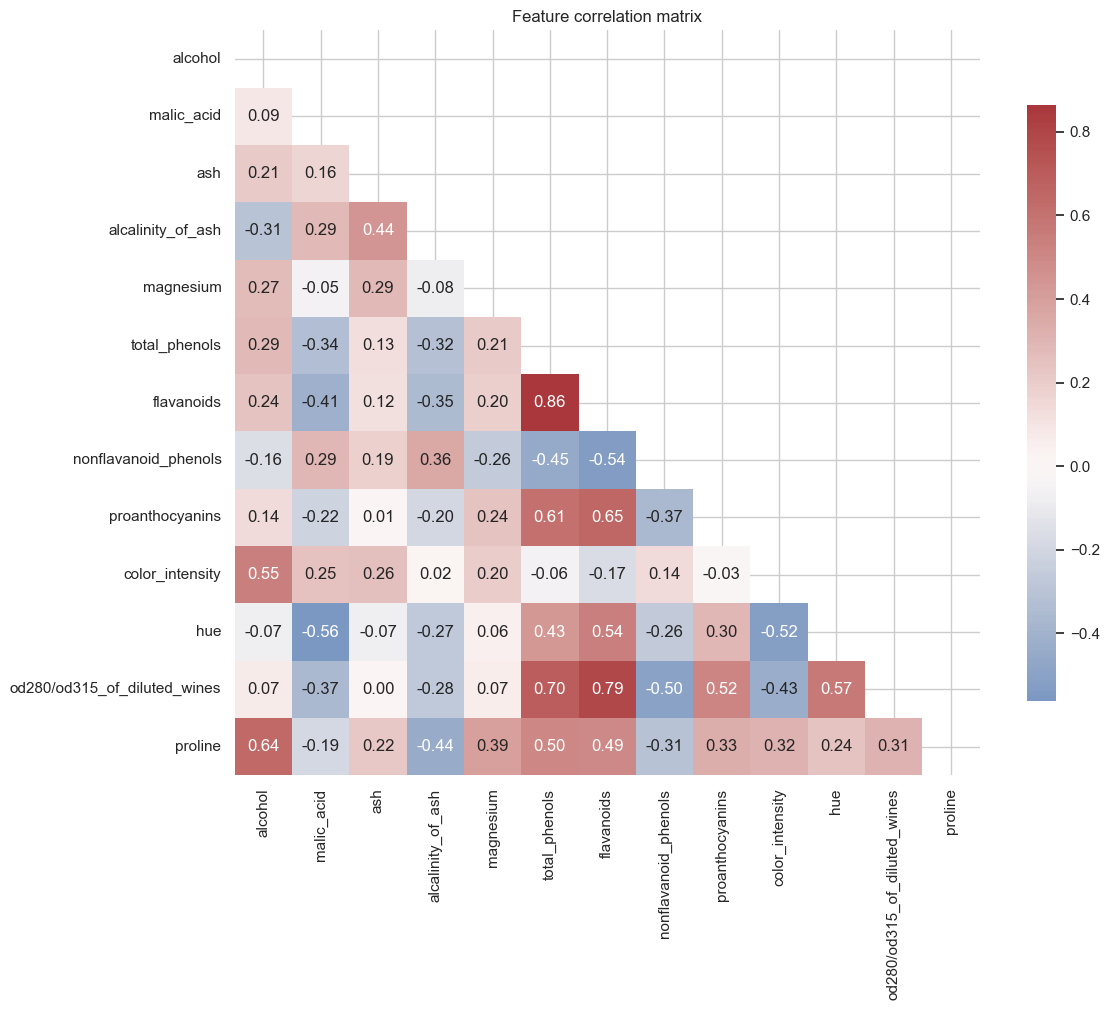

In [12]:
correlation = df[feature_names].corr()

plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(correlation, dtype=bool))
sns.heatmap(correlation, mask=mask, annot=True, fmt=".2f", cmap="vlag",
            center=0, square=True, cbar_kws={"shrink": 0.8})
plt.title("Feature correlation matrix")
plt.tight_layout()
plt.show()

In [13]:
pairs = (
    correlation.where(~np.eye(len(correlation), dtype=bool))
    .stack()
    .sort_values(key=abs, ascending=False)
    .drop_duplicates()
)
pairs.head(10).round(3)

total_phenols    flavanoids                      0.865
flavanoids       od280/od315_of_diluted_wines    0.787
total_phenols    od280/od315_of_diluted_wines    0.700
flavanoids       proanthocyanins                 0.653
proline          alcohol                         0.644
proanthocyanins  total_phenols                   0.612
hue              od280/od315_of_diluted_wines    0.565
malic_acid       hue                            -0.561
color_intensity  alcohol                         0.546
hue              flavanoids                      0.543
dtype: float64

### Pairwise relationships

A pairplot of the top discriminative features shows class separation and overlaps. With many features,
plot a subset to keep the figure readable.

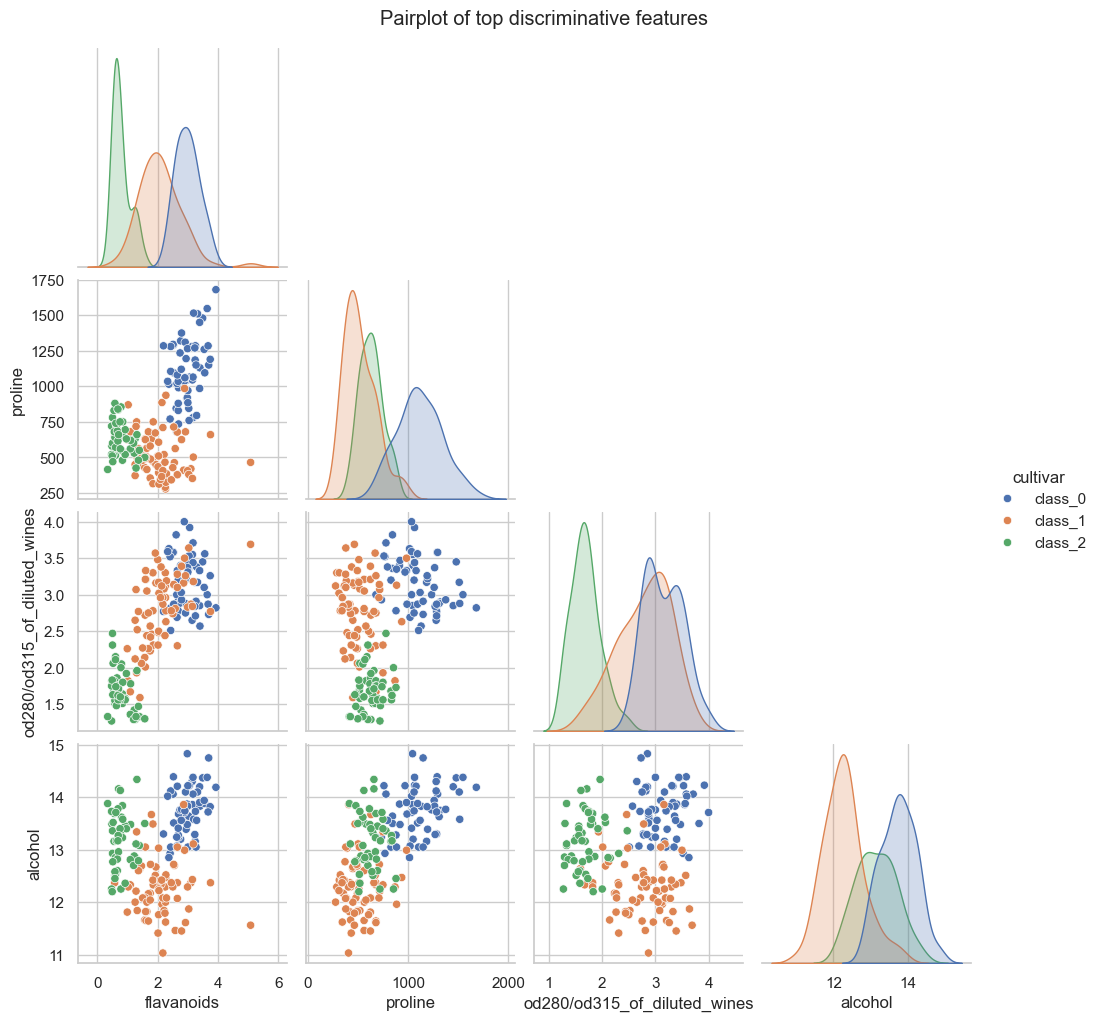

In [14]:
top_features = discrimination["feature"].head(4).tolist()
sns.pairplot(df[top_features + ["cultivar"]], hue="cultivar", corner=True, diag_kind="kde")
plt.suptitle("Pairplot of top discriminative features", y=1.02)
plt.show()

## 8. Outlier screening

Outliers can be genuine extremes or data errors. Screen them with the IQR rule and z-scores, then
investigate before deciding how to handle them.

- IQR rule: values below $Q1 - 1.5 \times IQR$ or above $Q3 + 1.5 \times IQR$.
- Z-score: values with $|z| > 3$ in approximately normal features.

In [15]:
iqr_counts = {}
for column in feature_names:
    q1, q3 = df[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_counts[column] = int(((df[column] < low) | (df[column] > high)).sum())

pd.Series(iqr_counts).sort_values(ascending=False)

alcalinity_of_ash               4
magnesium                       4
color_intensity                 4
malic_acid                      3
ash                             3
proanthocyanins                 2
hue                             1
alcohol                         0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

In [16]:
z_scores = (df[feature_names] - df[feature_names].mean()) / df[feature_names].std(ddof=0)
z_counts = (z_scores.abs() > 3).sum().sort_values(ascending=False)
print("Features with |z| > 3:")
print(z_counts[z_counts > 0])

Features with |z| > 3:
ash                  3
magnesium            2
malic_acid           1
alcalinity_of_ash    1
flavanoids           1
proanthocyanins      1
color_intensity      1
hue                  1
dtype: int64


Outliers are not automatically errors. In this dataset, extreme chemical measurements may be valid
samples. Deleting them blindly can remove rare but important cases. Consider robust models, clipping,
or separate analysis instead.

## 9. EDA checklist

- Shape, column names, types, and target definition.
- Missing values, duplicates, impossible ranges, and category consistency.
- Class balance and target leakage risks.
- Univariate distributions, skew, and scale differences.
- Relationships with the target.
- Correlation and multicollinearity.
- Outliers and their plausibility.
- Group structure and potential confounders.
- Validation strategy that matches how the model will be used.
- Documented findings and decisions.

## Key takeaways

- EDA is a structured investigation, not a single plot.
- Class-conditional summaries reveal useful predictors.
- Correlation helps detect redundancy but not causation.
- Outliers require investigation, not automatic removal.
- EDA findings should directly inform preprocessing, model choice, and validation.

## Exercises

1. Add a missing-value pattern to a copy of the data and visualise it.
2. Apply a log transform to the most skewed feature and compare its distribution.
3. Identify the pair of features with the strongest correlation and test dropping one.
4. Compare IQR and z-score outlier counts for `proline`.
5. Use a violin plot to compare `alcohol` across cultivars.
6. Write three modelling recommendations based on this EDA.